# 02 - Training Model Deteksi Promosi Judi Online

Melatih dan membandingkan 5 algoritma klasik untuk klasifikasi teks komentar YouTube:
**Naive Bayes, SVM, Random Forest, KNN, Logistic Regression**, ditambah **voting mayoritas** dari kelimanya
(cara yang dipakai worker pada sistem lama).

Alur:
1. Setup & load dataset Kaggle
2. Cleaning (fungsi yang **sama** dengan notebook 01 - scraping)
3. Deduplikasi -> split train/test -> balancing data latih
4. Training + evaluasi tiap model (TF-IDF + classifier dalam satu `Pipeline`)
5. Perbandingan model (tabel, heatmap, confusion matrix, ROC, FP/FN)
6. Analisis kesalahan & kata paling berpengaruh
7. Eksperimen: seberapa bersih teks sebaiknya? (uji ketahanan terhadap penyamaran non-ASCII)
8. Simpan model + informasi training (`models/`)

### Perbedaan dengan notebook lama (`Gambling_Trainer_kagle.ipynb`)
| Lama | Sekarang | Alasan |
|---|---|---|
| Training memakai `komentar_clean` buatan pembuat dataset | Cleaning ulang dari `komentar` dengan `clean_text` | cleaning saat training **harus sama** dengan saat prediksi data scraping |
| Tidak ada normalisasi Unicode | NFKC + tabel homoglif Unicode (1.200+ karakter) + huruf-emoji + small caps + gabung huruf dispasi | huruf "fancy", Cyrillic, & `P L U T O 8 8` adalah trik utama spam judi |
| Emoji & non-ASCII lain dibuang | Emoji -> token `emo_<nama>`, aksara lain -> `xxscript_<aksara>` | emoji seperti kantong uang / mesin slot bermakna; tidak ada yang dibuang diam-diam |
| - | Trik dicatat di **kolom `sinyal` terpisah** (`xxfancy`, `xxhomoglyph`, `xxspaced`, `xxdecor`, `xxleet`, `xxinvisible`) dan menjadi fitur biner | penyamaran itu sendiri adalah ciri promosi judi; teks bersih tetap enak dibaca |
| - | Leetspeak (`m4xw1n`) dibiarkan apa adanya, hanya ditandai `xxleet` | bentuk leet itu sendiri pola spam; normalisasi leet disimpan untuk NER nanti |
| TF-IDF di-fit ke seluruh data **sebelum** split | TF-IDF di dalam `Pipeline`, hanya belajar dari data latih | mencegah kebocoran informasi data uji |
| Undersampling seluruh data lalu split | Split dulu, undersampling **hanya data latih** | data uji mencerminkan distribusi asli |
| Duplikat template tidak dihapus | Deduplikasi sebelum split | kalimat yang sama tidak boleh ada di latih & uji sekaligus |
| Nilai FP/FN di grafik diketik manual | Dihitung dari confusion matrix | |
| Vectorizer & model disimpan terpisah | Satu file `Pipeline` per model | tidak mungkin salah pasang vectorizer |

## 1. Setup & load data

In [1]:
%pip install -q kagglehub emoji nltk anyascii

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import json
import os
import platform
import shutil
import time
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import kagglehub
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

RANDOM_STATE = 42
OUTPUT_DIR = "models"
pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os
import re
import unicodedata
import urllib.request

import emoji
import nltk
import pandas as pd
from anyascii import anyascii
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOPWORDS_ID = set(stopwords.words("indonesian"))

RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION_HASHTAG = re.compile(r"[@#]\w+")
RE_YT_EMOJI = re.compile(r":([a-z0-9]+(?:-[a-z0-9]+)+):")      # emoji khusus YouTube, mis. :face-blue-smiling:
RE_RI_RUN = re.compile("[\U0001F1E6-\U0001F1FF]{3,}")           # >= 3 huruf bendera berurutan = kata, bukan bendera
RE_NON_ASCII_RUN = re.compile(r"[^\x00-\x7f]+")
RE_ASCII_PUNCT = re.compile(r"[!-/:-@\[-^`{-~]")                 # tanda baca ASCII, kecuali "_" (dipakai token)
RE_SPACED = re.compile(r"\b(?:[a-z0-9] ){3,}[a-z0-9]\b")        # "p l u t o 8 8" (minimal 4 karakter)
RE_DOLAR_HURUF = re.compile(r"(?<=[a-z])\$|\$(?=[a-z])")   # "$" menempel huruf dipakai sebagai "s"
RE_LEET = re.compile(r"^[a-z]+[0-9]+[a-z][a-z0-9]*$")           # angka di tengah huruf: m4xw1n, sl0t

# Penanda trik penyamaran. Disimpan di KOLOM TERPISAH ("sinyal"), bukan ditempel ke teks, supaya teks bersih
# tetap enak dibaca. Saat training kolom ini menjadi fitur biner di samping TF-IDF teks.
SINYAL = {
    "xxfancy": "huruf gaya: bold/italic/fullwidth, small caps, huruf-emoji (huruf dalam kotak), huruf bendera berurutan",
    "xxhomoglyph": "huruf aksara lain yang bentuknya mirip Latin (Cyrillic, Yunani, Armenia, Cherokee, ...)",
    "xxspaced": "huruf yang dipisah spasi, mis. 'P L U T O 8 8'",
    "xxdecor": "simbol non-ASCII selain emoji, mis. blok, bintang, kurung dekoratif",
    "xxleet": "leetspeak: angka di tengah huruf (m4xw1n, sl0t - teksnya TIDAK diubah) atau $ sebagai s",
    "xxinvisible": "karakter tak terlihat (zero-width space, dsb.) yang diselipkan untuk memecah kata",
}

# ---------------------------------------------------------------------------------------------
# Tabel homoglif: Unicode confusables (TR39) = pemetaan resmi karakter yang BENTUKNYA mirip.
# Hanya aksara yang lazim dipakai menyamar yang diambil; Arab, CJK, dsb. tidak dipetakan
# supaya komentar asli berbahasa/beraksara lain tidak berubah jadi huruf Latin acak.
# ---------------------------------------------------------------------------------------------
URL_CONFUSABLES = "https://www.unicode.org/Public/security/latest/confusables.txt"
AKSARA_PENYAMAR = {"CYRILLIC", "GREEK", "ARMENIAN", "CHEROKEE", "LISU", "COPTIC", "LATIN", "MODIFIER",
                   "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL", "FULLWIDTH", "ROMAN"}
AKSARA_LATIN_GAYA = {"LATIN", "MODIFIER", "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL",
                     "FULLWIDTH", "ROMAN"}
# Karakter tak terlihat yang bisa diselipkan di tengah kata: zero-width space/joiner, word joiner, BOM, soft hyphen
KARAKTER_TAK_TERLIHAT = {chr(k) for k in (0x200B, 0x200C, 0x200D, 0x2060, 0xFEFF, 0x00AD)}
# Angka gaya: angka dalam lingkaran (hitam), kurung, titik, superscript, dsb. Angka aksara lain (Arab, Devanagari)
# TIDAK diubah karena bisa jadi bagian teks asli.
VARIATION_SELECTOR = {chr(0xFE0E), chr(0xFE0F)}
AKSARA_ANGKA_GAYA = {"DINGBAT", "CIRCLED", "NEGATIVE", "PARENTHESIZED", "DIGIT", "SUPERSCRIPT", "SUBSCRIPT",
                     "DOUBLE", "FULLWIDTH", "MATHEMATICAL"}
# Pelengkap: kemiripan visual yang TIDAK ada di confusables Unicode tetapi ditemukan lewat inventaris karakter
# (mis. lambda di "lambda-lexis17", increment/delta di "$<delta>MP<delta>H"). Tambahkan di sini jika menemukan trik baru.
TAMBAHAN_VISUAL = {chr(k): v for k, v in {
    0x3BB: "a", 0x39B: "a", 0x2206: "a", 0x394: "a",                # lambda, Lambda, increment, Delta
}.items()}
HOMOGLYPH_CADANGAN = {chr(k): v for k, v in {  # dipakai jika confusables.txt gagal diunduh
    0x430: "a", 0x435: "e", 0x43E: "o", 0x440: "p", 0x441: "c", 0x443: "y",     # Cyrillic
    0x445: "x", 0x43A: "k", 0x43C: "m", 0x442: "t", 0x43D: "h", 0x432: "b",
    0x456: "i", 0x458: "j", 0x455: "s", 0x501: "d",
    0x3B1: "a", 0x3BF: "o", 0x3B5: "e", 0x3B9: "i", 0x3BA: "k", 0x3BD: "v",     # Yunani
    0x3C1: "p", 0x3C4: "t", 0x3C5: "u", 0x3C7: "x",
}.items()}


def aksara(c):
    return unicodedata.name(c, "UNKNOWN").split()[0]


def muat_confusables(path="confusables.txt"):
    peta = dict(HOMOGLYPH_CADANGAN)
    try:
        if not os.path.exists(path):
            urllib.request.urlretrieve(URL_CONFUSABLES, path)
        with open(path, encoding="utf-8-sig") as f:
            for baris in f:
                baris = baris.split("#")[0].strip()
                if not baris:
                    continue
                src, tgt = [x.strip() for x in baris.split(";")[:2]]
                src = "".join(chr(int(h, 16)) for h in src.split())
                tgt = "".join(chr(int(h, 16)) for h in tgt.split())
                if (len(src) == 1 and not src.isascii() and tgt.isascii() and tgt.isalnum()
                        and aksara(src) in AKSARA_PENYAMAR):
                    peta[src] = tgt.lower()
    except Exception as e:
        print(f"confusables.txt tidak tersedia ({e}) - memakai {len(peta)} homoglif bawaan")
    peta.update(TAMBAHAN_VISUAL)
    return peta


HOMOGLYPH = muat_confusables()
print(f"Tabel homoglif: {len(HOMOGLYPH):,} karakter")


def _emoji_ke_token(e, data):
    nama = data["en"].strip(":").lower()
    nama = re.sub(r"_?(medium-light|medium-dark|light|medium|dark)_skin_tone", "", nama)
    return " emo_" + re.sub(r"[^a-z0-9]+", "_", nama).strip("_") + " "


def proses_teks(text, remove_stopwords=True, trace=False):
    """Cleaning lengkap. Mengembalikan (teks_bersih, sinyal, karakter_tak_dikenal, langkah)."""
    sinyal, tak_dikenal, langkah = set(), [], []

    def catat(nama, t):
        if trace:
            langkah.append((nama, t))

    if not isinstance(text, str):
        return "", sinyal, tak_dikenal, langkah
    t = text
    catat("0. asli", t)

    # 1. Huruf gaya (bold, italic, fullwidth, circled) -> huruf biasa dengan NFKC
    if any(not c.isascii() and unicodedata.normalize("NFKC", c).isascii()
           and unicodedata.normalize("NFKC", c).isalnum() for c in t):
        sinyal.add("xxfancy")
    t = unicodedata.normalize("NFKC", t)
    t = RE_URL.sub(" ", t)
    t = RE_MENTION_HASHTAG.sub(" ", t).replace("_", " ")
    catat("1. NFKC, hapus URL/mention", t)

    # 2. Huruf-emoji -> huruf: huruf dalam kotak hitam (U+1F150-1F189) dan huruf bendera berurutan
    #    (>= 3, agar pasangan bendera seperti Indonesia tetap dibaca sebagai bendera)
    def ri(m):
        return "".join(chr(ord(c) - 0x1F1E6 + ord("a")) for c in m.group())
    t2 = RE_RI_RUN.sub(ri, t)
    t2 = "".join(anyascii(c) if 0x1F150 <= ord(c) <= 0x1F189 else c for c in t2)
    if t2 != t:
        sinyal.add("xxfancy")
    t = t2
    catat("2. huruf-emoji -> huruf", t)

    # 3. Emoji -> token (TIDAK dihapus): kantong uang -> emo_money_bag
    t = RE_YT_EMOJI.sub(lambda m: " emo_" + m.group(1).replace("-", "_") + " ", t)
    t = emoji.replace_emoji(t, replace=_emoji_ke_token)
    catat("3. emoji -> token", t)

    # 4. Karakter tak terlihat dibuang TANPA spasi (memecah kata: "plu<ZWSP>to" -> "pluto"),
    #    lalu homoglif -> Latin (tabel confusables) dan huruf kecil
    if any(c in KARAKTER_TAK_TERLIHAT for c in t):
        sinyal.add("xxinvisible")
    t = "".join(c for c in t if c not in KARAKTER_TAK_TERLIHAT and c not in VARIATION_SELECTOR)
    for c in set(t):
        if c in HOMOGLYPH:
            sinyal.add("xxfancy" if aksara(c) in AKSARA_LATIN_GAYA else "xxhomoglyph")
    t = "".join(HOMOGLYPH.get(c, c) for c in t).lower()
    t2 = RE_DOLAR_HURUF.sub("s", t)            # "$ampah" -> "sampah" ("$100" tidak berubah)
    if t2 != t:
        sinyal.add("xxleet")
    t = t2
    catat("4. homoglif -> Latin", t)

    # 5. Aksen dibuang (cafe' -> cafe); huruf Latin lain (small caps, o-garis) -> ASCII;
    #    angka gaya (angka dalam lingkaran hitam, dsb.) -> angka biasa; tanda baca tipografis -> tanda baca ASCII
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))
    hasil = []
    for c in t:
        if c.isascii():
            hasil.append(c)
        elif aksara(c) == "LATIN":
            if "SMALL CAPITAL" in unicodedata.name(c, "") or unicodedata.name(c, "").startswith("LATIN LETTER"):
                sinyal.add("xxfancy")
            hasil.append(anyascii(c).lower())
        elif unicodedata.digit(c, None) is not None and aksara(c) in AKSARA_ANGKA_GAYA:
            sinyal.add("xxfancy")
            hasil.append(str(unicodedata.digit(c)))
        elif 0x2010 <= ord(c) <= 0x205E and unicodedata.category(c)[0] == "P":
            hasil.append(" ")  # blok General Punctuation (kutip miring, em dash, elipsis) = tanda baca biasa
        else:
            hasil.append(c)
    t = "".join(hasil)
    catat("5. aksen, Latin lain, angka gaya", t)

    # 6. Sisa non-ASCII TIDAK dihapus diam-diam: huruf aksara lain -> xxscript_<aksara>, simbol -> xxdecor
    def sisa(m):
        run = m.group()
        tak_dikenal.extend(run)
        huruf = [c for c in run if unicodedata.category(c)[0] in "LN"]
        if huruf:
            return f" xxscript_{aksara(huruf[0]).lower().replace('-', '_')} "
        if any(unicodedata.category(c)[0] in "SP" for c in run):
            sinyal.add("xxdecor")
        return " "
    t = RE_NON_ASCII_RUN.sub(sisa, t)
    catat("6. sisa non-ASCII -> token", t)

    # 7. Tanda baca ASCII dihapus, spasi dirapikan
    t = re.sub(r"\s+", " ", RE_ASCII_PUNCT.sub(" ", t)).strip()
    catat("7. hapus tanda baca ASCII", t)

    # 8. Gabung huruf yang dispasi: "p l u t o 8 8" -> "pluto88"
    t2 = RE_SPACED.sub(lambda m: m.group().replace(" ", ""), t)
    if t2 != t:
        sinyal.add("xxspaced")
    t = t2
    catat("8. gabung huruf dispasi", t)

    # 9. Leetspeak dibiarkan apa adanya (m4xw1n tetap m4xw1n), hanya ditandai
    tokens = t.split()
    if any(RE_LEET.match(tok) for tok in tokens):
        sinyal.add("xxleet")

    # 10. Stopword Bahasa Indonesia
    if remove_stopwords:
        tokens = [tok for tok in tokens if tok not in STOPWORDS_ID]
    catat("10. hapus stopword", " ".join(tokens))

    hasil_akhir = " ".join(tokens)
    catat("11. kolom sinyal (terpisah)", " ".join(sorted(sinyal)) or "-")
    return hasil_akhir, sinyal, tak_dikenal, langkah


def clean_text(text, remove_stopwords=True):
    """Teks bersih yang enak dibaca (tanpa token sinyal). Sinyal: obfuscation_signals()."""
    return proses_teks(text, remove_stopwords)[0]


def light_clean(text):
    """Cleaning minimal untuk model karakter n-gram: huruf kecil, URL, mention. Non-ASCII DIBIARKAN."""
    text = RE_URL.sub(" ", str(text).lower())
    text = RE_MENTION_HASHTAG.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


def siapkan_input(texts):
    """Input model (training maupun prediksi): DataFrame berkolom text_clean, sinyal, text_min."""
    texts = pd.Series(texts) if not isinstance(texts, pd.Series) else texts
    hasil = texts.apply(proses_teks)
    return pd.DataFrame({
        "text_clean": hasil.str[0],
        "sinyal": hasil.str[1].apply(lambda s: " ".join(sorted(s))),
        "text_min": texts.apply(light_clean),
    }, index=texts.index)


def obfuscation_signals(text):
    return proses_teks(text)[1]


def karakter_tak_dikenal(text):
    return proses_teks(text)[2]


def tampilkan_langkah(text):
    for nama, isi in proses_teks(text, trace=True)[3]:
        print(f"{nama:30s} | {isi}")
    print()

Tabel homoglif: 1,276 karakter


In [4]:
path = kagglehub.dataset_download("yaemico/judionline")
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv_file)
print(df.shape)
df[["komentar", "label"]].head()

(10230, 9)


,komentar,label
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1
1,Paling suka model H2 😍🔥,0
2,Mobilnya udah hancur 🥺,0
3,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1
4,Semoga lekas recover mobilnya mas Dipo,0


## 2. Cleaning

Fungsi `clean_text` (versi 2) identik dengan notebook 01. Contoh langkah demi langkah ada di notebook 01 bagian 4.
Tabel homoglif diambil dari `confusables.txt` resmi Unicode (diunduh otomatis).

In [5]:
# siapkan_input() = fungsi yang sama dipakai notebook 01 saat prediksi
df = df.join(siapkan_input(df["komentar"]))      # kolom baru: text_clean, sinyal, text_min

contoh = df[df["komentar"].str.len() > 30].groupby("label").sample(3, random_state=7)
for _, r in contoh.iterrows():
    print(f"[label {r['label']}]")
    print("  komentar       :", r["komentar"])
    print("  komentar_clean :", r["komentar_clean"], "  <- versi dataset")
    print("  text_clean     :", r["text_clean"], "  <- versi kita")
    print("  sinyal         :", r["sinyal"] or "-")

print()
print("Isi kolom sinyal:")
for k, v in SINYAL.items():
    print(f"  {k:12s} {v}")

[label 0]
  komentar       :  @hanifalii23  saya cuma asal tag bang,kflgy
  komentar_clean : saya cuma asal tag bang , kflgy   <- versi dataset
  text_clean     : tag bang kflgy   <- versi kita
  sinyal         : -
[label 0]
  komentar       : Entah lah bang, mau apa coba mereka menjabat 😅.
  komentar_clean : entah lah bang , mau apa coba mereka menjabat .   <- versi dataset
  text_clean     : bang coba menjabat emo_grinning_face_with_sweat   <- versi kita
  sinyal         : -
[label 0]
  komentar       : Beli ini cuman buat telpon dan wa 😅
  komentar_clean : beli ini cuman buat telpon dan wa   <- versi dataset
  text_clean     : beli cuman telpon wa emo_grinning_face_with_sweat   <- versi kita
  sinyal         : -
[label 1]
  komentar       : Gas tu gan mandalika77 zeusnya nya galak tu, lagi mau aja tu ngasi gw baru dikasi maxwin
  komentar_clean : gas tu gan mandalika77 zeusnya nya galak tu , aja tu ngasi gw dikasi maxwin   <- versi dataset
  text_clean     : gas tu gan mandalika77 z

## 3. Deduplikasi, split, dan balancing

In [6]:
n_awal = len(df)
data = df[(df["text_clean"].str.len() > 0) | (df["sinyal"].str.len() > 0)]
n_tidak_kosong = len(data)

# Duplikat = teks bersih DAN sinyal sama. Jika labelnya berbeda, ambil label mayoritas
data = (data.groupby(["text_clean", "sinyal"], as_index=False)
            .agg(label=("label", lambda s: int(s.mean() >= 0.5)),
                 text_min=("text_min", "first"), komentar=("komentar", "first")))

print(f"Data awal             : {n_awal:,}")
print(f"Setelah buang kosong  : {n_tidak_kosong:,}")
print(f"Setelah deduplikasi   : {len(data):,}  (dibuang {n_tidak_kosong - len(data):,} duplikat)")
print()
print(data["label"].value_counts().rename(NAMA_LABEL))

Data awal             : 10,230
Setelah buang kosong  : 10,216
Setelah deduplikasi   : 8,753  (dibuang 1,463 duplikat)

label
Normal (0)          5965
Promosi judi (1)    2788
Name: count, dtype: int64


In [7]:
KOLOM_INPUT = ["text_clean", "sinyal", "text_min"]
X_train_full, X_test, y_train_full, y_test = train_test_split(
    data[KOLOM_INPUT], data["label"], test_size=0.2, stratify=data["label"], random_state=RANDOM_STATE)

# Undersampling kelas mayoritas HANYA pada data latih
train = X_train_full.assign(label=y_train_full)
n_min = train["label"].value_counts().min()
train_bal = (train.groupby("label").sample(n=n_min, random_state=RANDOM_STATE)
                  .sample(frac=1, random_state=RANDOM_STATE))
X_train, y_train = train_bal[KOLOM_INPUT], train_bal["label"]

ringkas_split = pd.DataFrame({
    "train (sebelum balancing)": y_train_full.value_counts(),
    "train (setelah balancing)": y_train.value_counts(),
    "test": y_test.value_counts(),
}).rename(index=NAMA_LABEL)
ringkas_split.loc["Total"] = ringkas_split.sum()
ringkas_split

,train (sebelum balancing),train (setelah balancing),test
label,,,
Normal (0),4772,2230,1193
Promosi judi (1),2230,2230,558
Total,7002,4460,1751


## 4. Training & evaluasi

Setiap model adalah `Pipeline(fitur -> classifier)`, dengan fitur = **TF-IDF kolom `text_clean`** digabung
**fitur biner kolom `sinyal`** (1 kolom per jenis trik). Untuk tiap model dicatat:
- **CV F1 (5-fold)** pada data latih - seberapa stabil model
- **Accuracy, Precision, Recall, F1, ROC-AUC** pada data uji (kelas positif = promosi judi)
- waktu training

Random Forest memakai `GridSearchCV` seperti notebook lama. SVM dibungkus `CalibratedClassifierCV` untuk mendapatkan probabilitas
(`SVC(probability=True)` sudah deprecated di scikit-learn terbaru).

In [8]:
def tfidf():
    return TfidfVectorizer(max_features=5000)

def vektor_sinyal():
    # satu fitur biner per jenis trik; kosakata tetap supaya urutan fitur selalu sama
    return CountVectorizer(binary=True, lowercase=False, token_pattern=r"\S+", vocabulary=list(SINYAL))

def fitur():
    return ColumnTransformer([("teks", tfidf(), "text_clean"), ("sinyal", vektor_sinyal(), "sinyal")])

MODELS = {
    "Naive Bayes": Pipeline([("fitur", fitur()), ("clf", MultinomialNB())]),
    "SVM": Pipeline([("fitur", fitur()), ("clf", CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False))]),
    "Random Forest": GridSearchCV(
        Pipeline([("fitur", fitur()), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        param_grid={"clf__n_estimators": [100, 200], "clf__max_depth": [10, None], "clf__min_samples_split": [2, 5]},
        cv=3, scoring="f1", n_jobs=-1),
    "KNN": Pipeline([("fitur", fitur()), ("clf", KNeighborsClassifier())]),
    "Logistic Regression": Pipeline([("fitur", fitur()), ("clf", LogisticRegression(max_iter=1000))]),
}

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fitted, hasil, prediksi = {}, {}, {}

for nama, model in MODELS.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    waktu = time.time() - t0

    if isinstance(model, GridSearchCV):
        print(f"[{nama}] parameter terbaik: {model.best_params_}")
        model = model.best_estimator_
    cv_f1 = cross_val_score(clone(model), X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    fitted[nama] = model
    prediksi[nama] = (y_pred, y_prob)
    hasil[nama] = {
        "CV F1 (mean)": cv_f1.mean(),
        "CV F1 (std)": cv_f1.std(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Waktu training (s)": waktu,
    }
    print(f"[{nama}] selesai dalam {waktu:.1f}s - F1 uji {hasil[nama]['F1']:.4f}")
    print(classification_report(y_test, y_pred, target_names=["normal", "judi"], digits=4))

[Naive Bayes] selesai dalam 0.0s - F1 uji 0.9101
              precision    recall  f1-score   support

      normal     0.9945    0.9137    0.9524      1193
        judi     0.8427    0.9892    0.9101       558

    accuracy                         0.9377      1751
   macro avg     0.9186    0.9515    0.9313      1751
weighted avg     0.9462    0.9377    0.9389      1751



[SVM] selesai dalam 3.0s - F1 uji 0.9757
              precision    recall  f1-score   support

      normal     0.9875    0.9899    0.9887      1193
        judi     0.9784    0.9731    0.9757       558

    accuracy                         0.9846      1751
   macro avg     0.9829    0.9815    0.9822      1751
weighted avg     0.9846    0.9846    0.9846      1751



[Random Forest] parameter terbaik: {'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}


[Random Forest] selesai dalam 5.5s - F1 uji 0.9713
              precision    recall  f1-score   support

      normal     0.9858    0.9874    0.9866      1193
        judi     0.9730    0.9695    0.9713       558

    accuracy                         0.9817      1751
   macro avg     0.9794    0.9785    0.9789      1751
weighted avg     0.9817    0.9817    0.9817      1751



[KNN] selesai dalam 0.0s - F1 uji 0.8372
              precision    recall  f1-score   support

      normal     0.8909    0.9858    0.9359      1193
        judi     0.9606    0.7419    0.8372       558

    accuracy                         0.9081      1751
   macro avg     0.9257    0.8638    0.8866      1751
weighted avg     0.9131    0.9081    0.9045      1751



[Logistic Regression] selesai dalam 0.1s - F1 uji 0.9634
              precision    recall  f1-score   support

      normal     0.9745    0.9925    0.9834      1193
        judi     0.9832    0.9444    0.9634       558

    accuracy                         0.9772      1751
   macro avg     0.9788    0.9685    0.9734      1751
weighted avg     0.9773    0.9772    0.9770      1751



### Voting mayoritas

Worker lama menggabungkan kelima model dengan voting: komentar dianggap promosi jika **>= 3 dari 5** model memprediksi 1.

In [10]:
votes = np.vstack([prediksi[n][0] for n in fitted])
y_vote = (votes.mean(axis=0) >= 0.5).astype(int)
y_vote_prob = np.vstack([prediksi[n][1] for n in fitted]).mean(axis=0)
prediksi["Voting (5 model)"] = (y_vote, y_vote_prob)
hasil["Voting (5 model)"] = {
    "CV F1 (mean)": np.nan, "CV F1 (std)": np.nan,
    "Accuracy": accuracy_score(y_test, y_vote),
    "Precision": precision_score(y_test, y_vote),
    "Recall": recall_score(y_test, y_vote),
    "F1": f1_score(y_test, y_vote),
    "ROC-AUC": roc_auc_score(y_test, y_vote_prob),
    "Waktu training (s)": sum(h["Waktu training (s)"] for h in hasil.values()),
}
print(classification_report(y_test, y_vote, target_names=["normal", "judi"], digits=4))

              precision    recall  f1-score   support

      normal     0.9842    0.9916    0.9879      1193
        judi     0.9818    0.9659    0.9738       558

    accuracy                         0.9834      1751
   macro avg     0.9830    0.9788    0.9808      1751
weighted avg     0.9834    0.9834    0.9834      1751



## 5. Perbandingan model

In [11]:
metrics_df = pd.DataFrame(hasil).T.sort_values("F1", ascending=False)
metrics_df.style.format("{:.4f}").format("{:.1f}", subset=["Waktu training (s)"]).background_gradient(
    cmap="Blues", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

,CV F1 (mean),CV F1 (std),Accuracy,Precision,Recall,F1,ROC-AUC,Waktu training (s)
SVM,0.9802,0.0011,0.9846,0.9784,0.9731,0.9757,0.9980,3.0
Voting (5 model),nan,nan,0.9834,0.9818,0.9659,0.9738,0.9972,8.6
Random Forest,0.9791,0.0013,0.9817,0.9730,0.9695,0.9713,0.9975,5.5
Logistic Regression,0.9635,0.0040,0.9772,0.9832,0.9444,0.9634,0.9966,0.1
Naive Bayes,0.9553,0.0048,0.9377,0.8427,0.9892,0.9101,0.9949,0.0
KNN,0.9419,0.0050,0.9081,0.9606,0.7419,0.8372,0.9268,0.0


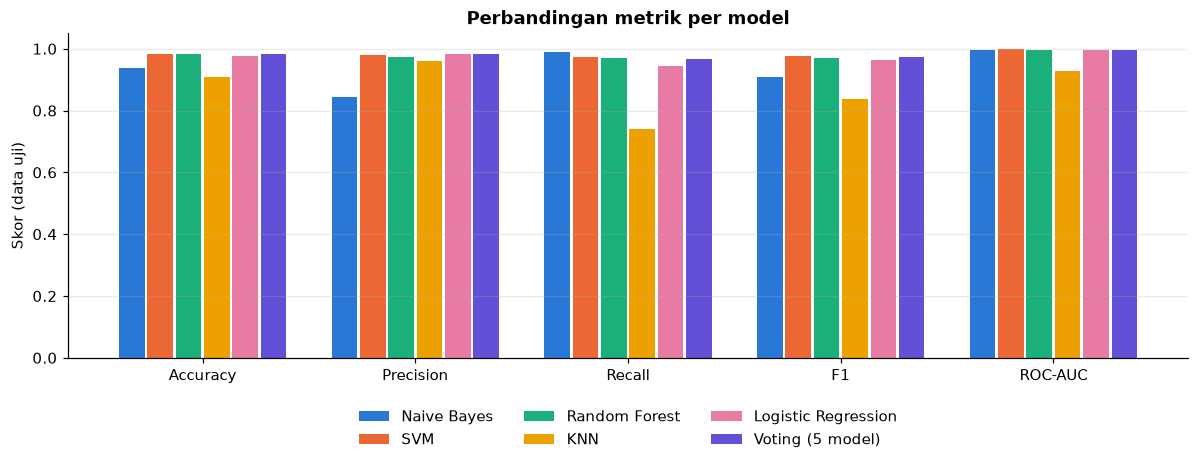

In [12]:
METRIK = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
urutan = list(hasil)  # urutan tetap -> warna tiap model selalu sama

fig, ax = plt.subplots(figsize=(11, 4.5))
lebar = 0.8 / len(urutan)
for i, nama in enumerate(urutan):
    x = np.arange(len(METRIK)) + i * lebar - 0.4 + lebar / 2
    ax.bar(x, [hasil[nama][m] for m in METRIK], width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(METRIK)), METRIK)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Skor (data uji)")
ax.set_title("Perbandingan metrik per model")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

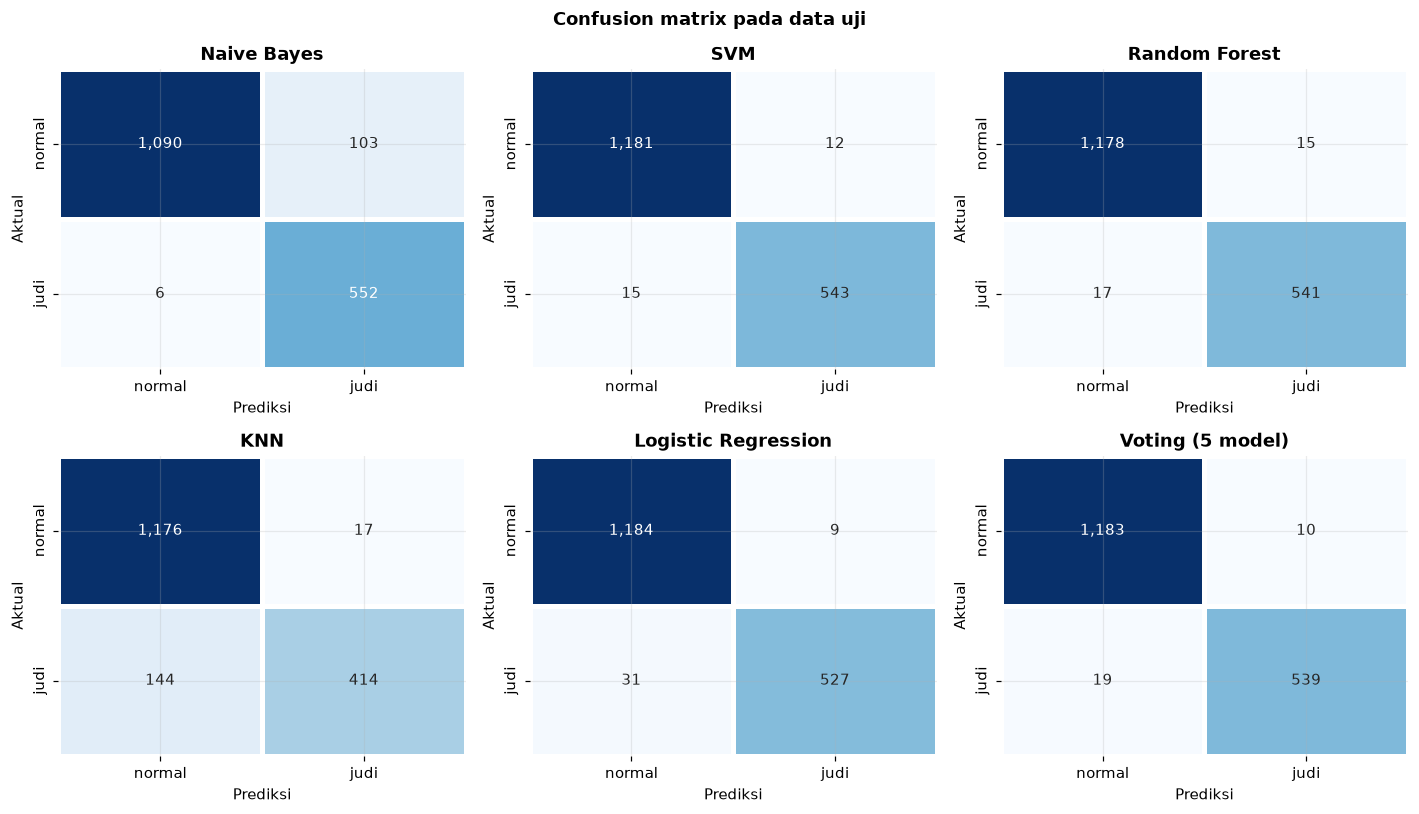

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, nama in zip(axes.ravel(), urutan):
    cm = confusion_matrix(y_test, prediksi[nama][0])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white",
                xticklabels=["normal", "judi"], yticklabels=["normal", "judi"])
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.suptitle("Confusion matrix pada data uji", fontweight="bold")
plt.tight_layout()
plt.show()

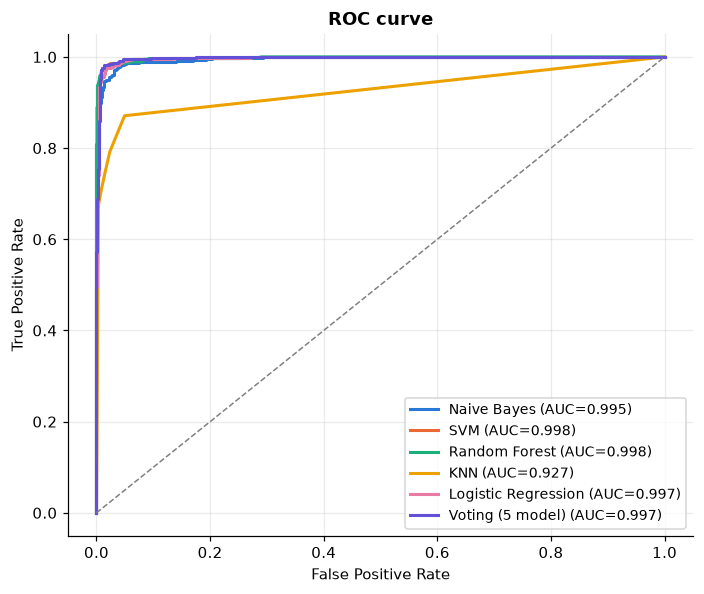

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for i, nama in enumerate(urutan):
    fpr, tpr, _ = roc_curve(y_test, prediksi[nama][1])
    ax.plot(fpr, tpr, color=WARNA_MODEL[i], lw=2, label=f"{nama} (AUC={hasil[nama]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**False Positive** = komentar normal yang dituduh promosi judi (mengganggu pengguna asli).
**False Negative** = promosi judi yang lolos.

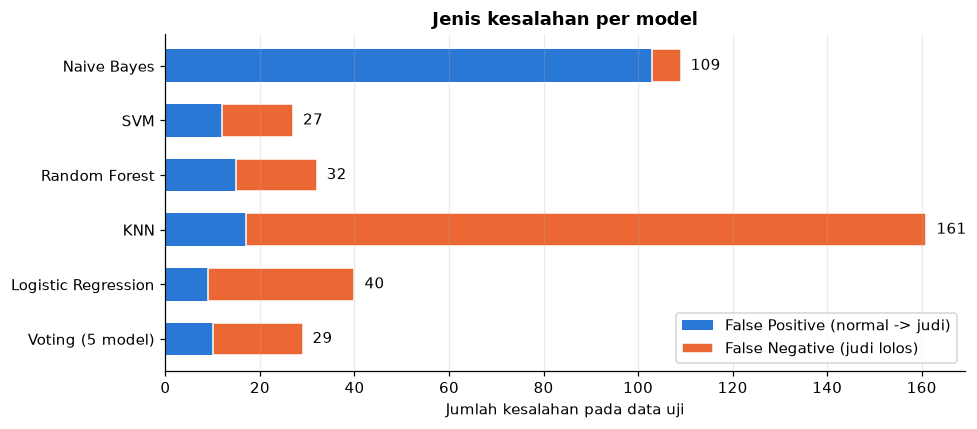

,TN,FP,FN,TP,Total salah
Naive Bayes,1090,103,6,552,109
SVM,1181,12,15,543,27
Random Forest,1178,15,17,541,32
KNN,1176,17,144,414,161
Logistic Regression,1184,9,31,527,40
Voting (5 model),1183,10,19,539,29


In [15]:
fpfn = pd.DataFrame({
    nama: dict(zip(["TN", "FP", "FN", "TP"], confusion_matrix(y_test, prediksi[nama][0]).ravel()))
    for nama in urutan}).T
fpfn["Total salah"] = fpfn["FP"] + fpfn["FN"]

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(fpfn))
ax.barh(y, fpfn["FP"], color=WARNA_LABEL[0], height=0.6, label="False Positive (normal -> judi)")
ax.barh(y, fpfn["FN"], left=fpfn["FP"], color=WARNA_LABEL[1], height=0.6, label="False Negative (judi lolos)",
        edgecolor="white", linewidth=1)
for yi, total in zip(y, fpfn["Total salah"]):
    ax.text(total, yi, f"  {total}", va="center")
ax.set_yticks(y, fpfn.index)
ax.invert_yaxis()
ax.set_xlabel("Jumlah kesalahan pada data uji")
ax.set_title("Jenis kesalahan per model")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
fpfn

## 6. Analisis kesalahan & interpretasi

In [16]:
terbaik = metrics_df.drop(index="Voting (5 model)").index[0]
print("Model tunggal terbaik (F1):", terbaik)

salah = X_test[["text_clean", "sinyal"]].assign(aktual=y_test, prediksi=prediksi[terbaik][0],
                                                prob_judi=prediksi[terbaik][1])
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("prob_judi")
print(f"Jumlah salah: {len(salah)}")
salah

Model tunggal terbaik (F1): SVM
Jumlah salah: 27


,text_clean,sinyal,aktual,prediksi,prob_judi
8544,ya allah semoga komentar promosi dora77 panggil mu secepat amin,,1,0,0.030009
4855,lihat episode2 sblmnya emg klu kesannya kayak keburu buru touringx,,1,0,0.046979
1485,best coach sih,,1,0,0.052937
6268,orang trump menang pilpres ya,,1,0,0.097126
1892,coocaa best sih,,1,0,0.125430
401,65inch aja udah gede bener jir,,1,0,0.140542
3724,iklan judul bikin darah,,1,0,0.152541
1417,berhenti ngehalu,,1,0,0.188994
7829,terbaik sih gak pelit pelit,,1,0,0.262853
8199,udh nomor 1 dijegal,,1,0,0.300978


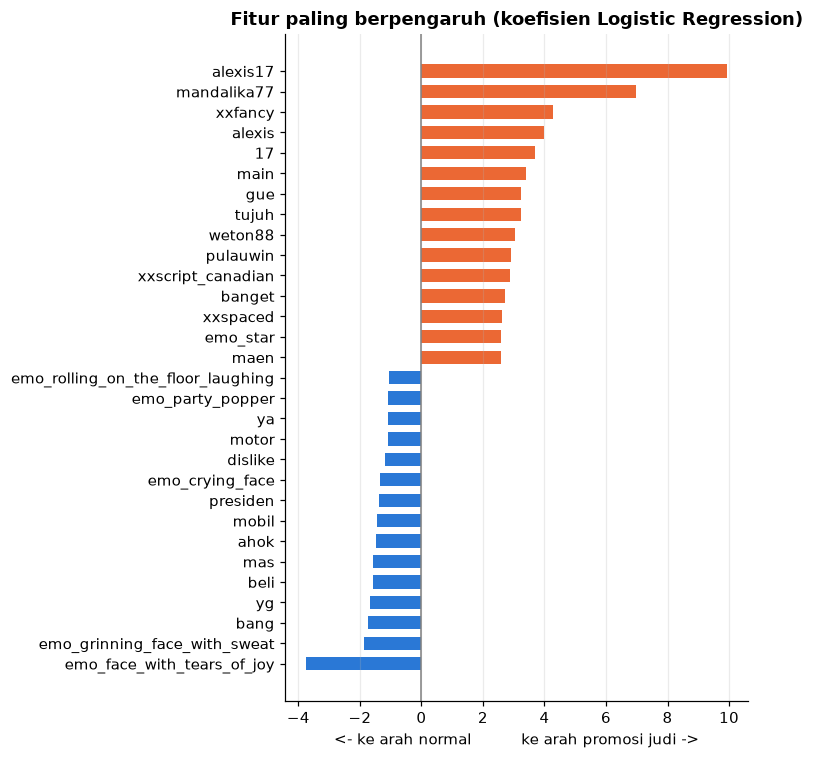

In [17]:
# Logistic Regression: koefisien positif -> mendorong ke "judi", negatif -> ke "normal"
lr = fitted["Logistic Regression"]
kata = np.array([f.split("__", 1)[1] for f in lr.named_steps["fitur"].get_feature_names_out()])
coef = lr.named_steps["clf"].coef_[0]
idx = np.argsort(coef)
top = pd.concat([pd.Series(coef[idx[:15]], kata[idx[:15]]), pd.Series(coef[idx[-15:]], kata[idx[-15:]])])

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top.index, top.values, color=[WARNA_LABEL[int(v > 0)] for v in top.values], height=0.65)
ax.axvline(0, color="gray", lw=1)
ax.set_title("Fitur paling berpengaruh (koefisien Logistic Regression)")
ax.set_xlabel("<- ke arah normal          ke arah promosi judi ->")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Uji coba kalimat baru

Termasuk trik huruf fancy/dispasi dan **nama situs yang tidak ada di dataset** (`zeus123`) untuk melihat keterbatasan model.
Huruf fancy ditulis dengan escape `\U...` agar sel ini tetap aman disalin.

In [18]:
kalimat = [
    "videonya keren banget bang, lanjutkan",
    "mobilnya bagus, kapan review yang versi listrik?",
    "auto jepe main di pluto88 modal receh",
    "\U0001d407\U0001d40e\U0001d40a\U0001d408 terus di \U0001d40f\U0001d40b\U0001d414\U0001d413\U0001d40e\U0001d7d6\U0001d7d6",  # HOKI ... PLUTO88 (huruf bold)
    "gas main di A L E X I S 1 7 pasti wd",
    "berkat zeus123 rezeki ngalir terus",
]
masukan = siapkan_input(kalimat)
uji = pd.DataFrame({"kalimat": kalimat, "text_clean": masukan["text_clean"], "sinyal": masukan["sinyal"]})
for nama, m in fitted.items():
    uji[nama] = m.predict(masukan)
uji["Voting"] = (uji[list(fitted)].mean(axis=1) >= 0.5).astype(int)
uji

,kalimat,text_clean,sinyal,Naive Bayes,SVM,Random Forest,KNN,Logistic Regression,Voting
0,"videonya keren banget bang, lanjutkan",videonya keren banget bang lanjutkan,,0,0,0,0,0,0
1,"mobilnya bagus, kapan review yang versi listrik?",mobilnya bagus review versi listrik,,0,0,0,0,0,0
2,auto jepe main di pluto88 modal receh,auto jepe main pluto88 modal receh,,1,1,1,0,1,1
3,𝐇𝐎𝐊𝐈 terus di 𝐏𝐋𝐔𝐓𝐎𝟖𝟖,hoki pluto88,xxfancy,1,1,1,1,1,1
4,gas main di A L E X I S 1 7 pasti wd,gas main alexis17 wd,xxspaced,1,1,1,1,1,1
5,berkat zeus123 rezeki ngalir terus,berkat zeus123 rezeki ngalir,,1,1,1,0,0,1


## 7. Eksperimen: seberapa bersih teks sebaiknya?

Promosi judi sering memakai karakter non-ASCII untuk menyamarkan kata kunci. Membersihkan terlalu agresif menghilangkan sinyal itu,
tetapi tidak membersihkan sama sekali membuat `PLUTO88` versi huruf bold menjadi token yang berbeda dari `pluto88`.
Lima pendekatan dibandingkan (semua memakai Logistic Regression agar adil dan cepat):

| Varian | Input | Fitur |
|---|---|---|
| 0. Cleaning v1 (sebelum perbaikan) | NFKC + 26 homoglif manual; emoji & non-ASCII lain **dihapus** | TF-IDF kata |
| A. Kata, tanpa sinyal | kolom `text_clean` saja | TF-IDF kata |
| B. Kata + kolom sinyal (**default**) | `text_clean` + `sinyal` | TF-IDF kata + fitur biner sinyal |
| C. Karakter, cleaning minimal | `text_min`: huruf kecil saja, **semua non-ASCII dibiarkan** | TF-IDF karakter 2-5 gram |
| D. Gabungan B + C | ketiganya | TF-IDF kata + sinyal + karakter |

Selain data uji biasa, komentar promosi di data uji juga **disamarkan secara sintetis** untuk menguji ketahanan:
- **bold**: semua huruf/angka diganti huruf Mathematical Bold
- **homoglif**: huruf a, e, o, p, c, x diganti huruf Cyrillic yang mirip
- **homoglif campuran**: a, o, i, n diganti huruf Yunani/Armenia/Cherokee yang mirip (tidak ada di tabel manual v1)
- **small caps**: semua huruf diganti huruf kapital kecil (`maxwin` -> small caps)
- **spasi**: nama situs (`alexis17`) ditulis `a l e x i s 1 7`
- **huruf-emoji**: huruf pada nama situs diganti huruf dalam kotak hitam (blok emoji)

Fungsi cleaning versi lama (v1) disalin di sini hanya sebagai pembanding.

In [19]:
RE_NON_ALNUM_V1 = re.compile(r"[^0-9a-z\s]")
RE_SPACED_V1 = re.compile(r"\b(?:\w ){3,}\w\b")
TABEL_HOMOGLYPH_V1 = str.maketrans(HOMOGLYPH_CADANGAN)


def clean_text_v1(text):
    # NFKC + 26 homoglif manual; emoji & non-ASCII lain DIHAPUS; sinyal xxfancy/xxhomoglyph/xxspaced/xxdecor
    if not isinstance(text, str):
        return ""
    sinyal = set()
    for c in text:
        if c.isascii() or c.isspace():
            continue
        n = unicodedata.normalize("NFKC", c)
        if n.isascii():
            if n.isalnum():
                sinyal.add("xxfancy")
        elif c.lower() in HOMOGLYPH_CADANGAN:
            sinyal.add("xxhomoglyph")
        elif not (emoji.is_emoji(c) or unicodedata.category(c) in ("Mn", "Me", "Cf", "Sk")
                  or unicodedata.name(c, "").startswith("LATIN")):
            sinyal.add("xxdecor")
    t = unicodedata.normalize("NFKC", text)
    t = emoji.replace_emoji(t, replace=" ")
    t = re.sub(r":[a-z0-9]+(?:-[a-z0-9]+)+:", " ", t)
    t = t.lower().translate(TABEL_HOMOGLYPH_V1)
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))
    t = RE_MENTION_HASHTAG.sub(" ", RE_URL.sub(" ", t))
    t = re.sub(r"\s+", " ", RE_NON_ALNUM_V1.sub(" ", t)).strip()
    t2 = RE_SPACED_V1.sub(lambda m: m.group().replace(" ", ""), t)
    if t2 != t:
        sinyal.add("xxspaced")
    tokens = [tok for tok in t2.split() if tok not in STOPWORDS_ID]
    return " ".join(tokens + sorted(sinyal))

In [20]:
BOLD = {**{chr(ord("A") + i): chr(0x1D400 + i) for i in range(26)},
        **{chr(ord("a") + i): chr(0x1D41A + i) for i in range(26)},
        **{chr(ord("0") + i): chr(0x1D7CE + i) for i in range(10)}}
CYRILLIC = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "p": "\u0440", "c": "\u0441", "x": "\u0445"}
CAMPURAN = {"a": "\u03b1", "o": "\u0585", "i": "\u13a5", "n": "\u0578"}   # Yunani, Armenia, Cherokee, Armenia
SMALLCAPS = dict(zip("abcdefghijklmnopqrstuvwxyz",
                     "\u1d00\u0299\u1d04\u1d05\u1d07\ua730\u0262\u029c\u026a\u1d0a\u1d0b\u029f\u1d0d"
                     "\u0274\u1d0f\u1d18\u01eb\u0280\ua731\u1d1b\u1d1c\u1d20\u1d21x\u028f\u1d22"))
HURUF_EMOJI = {chr(ord("a") + i): chr(0x1F170 + i) for i in range(26)}
RE_BRAND = re.compile(r"\b[A-Za-z]+\d{2,}\b")
JENIS_SAMARAN = ["bold", "homoglif", "homoglif campuran", "small caps", "spasi", "huruf-emoji"]

def samarkan(text, cara):
    if cara == "bold":
        return text.translate(str.maketrans(BOLD))
    if cara == "homoglif":
        return text.translate(str.maketrans(CYRILLIC))
    if cara == "homoglif campuran":
        return text.translate(str.maketrans(CAMPURAN))
    if cara == "small caps":
        return text.lower().translate(str.maketrans(SMALLCAPS))
    if cara == "spasi":
        return RE_BRAND.sub(lambda m: " ".join(m.group()), text)
    if cara == "huruf-emoji":
        return RE_BRAND.sub(lambda m: m.group().lower().translate(str.maketrans(HURUF_EMOJI)), text)
    return text

In [21]:
# light_clean() (cleaning minimal) didefinisikan di sel cleaning di atas
contoh_brand = "gas main di alexis17 pasti jp"
for cara in JENIS_SAMARAN:
    t = samarkan(contoh_brand, cara)
    print(f"{cara:18s} {t!r:38s} -> v2 {clean_text(t)!r:24s} sinyal={sorted(obfuscation_signals(t))} | v1 {clean_text_v1(t)!r}")

bold               '𝐠𝐚𝐬 𝐦𝐚𝐢𝐧 𝐝𝐢 𝐚𝐥𝐞𝐱𝐢𝐬𝟏𝟕 𝐩𝐚𝐬𝐭𝐢 𝐣𝐩'        -> v2 'gas main alexis17 jp'   sinyal=['xxfancy'] | v1 'gas main alexis17 jp xxfancy'
homoglif           'gаs mаin di аlехis17 раsti jр'        -> v2 'gas main alexis17 jp'   sinyal=['xxhomoglyph'] | v1 'gas main alexis17 jp xxhomoglyph'
homoglif campuran  'gαs mαᎥո dᎥ αlexᎥs17 pαstᎥ jp'        -> v2 'gas main alexis17 jp'   sinyal=['xxhomoglyph'] | v1 'gas ma d alex s17 past jp xxdecor xxhomoglyph'
small caps         'ɢᴀꜱ ᴍᴀɪɴ ᴅɪ ᴀʟᴇxɪꜱ17 ᴘᴀꜱᴛɪ ᴊᴘ'        -> v2 'gas main alexis17 jp'   sinyal=['xxfancy'] | v1 'x 17'
spasi              'gas main di a l e x i s 1 7 pasti jp' -> v2 'gas main alexis17 jp'   sinyal=['xxspaced'] | v1 'gas main alexis17 jp xxspaced'
huruf-emoji        'gas main di 🅰🅻🅴🆇🅸🆂17 pasti jp'        -> v2 'gas main alexis17 jp'   sinyal=['xxfancy'] | v1 'gas main 17 jp xxdecor'


In [22]:
def kolom(idx):
    d = data.loc[idx, KOLOM_INPUT + ["komentar"]].copy()
    d["text_v1"] = d["komentar"].apply(clean_text_v1)
    return d

D_train, D_test = kolom(X_train.index), kolom(X_test.index)

def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=50000, sublinear_tf=True)

def lr():
    return LogisticRegression(max_iter=2000)

VARIAN = {
    "0. Cleaning v1 (sebelumnya)": Pipeline([("fitur", ColumnTransformer([("w", tfidf(), "text_v1")])), ("clf", lr())]),
    "A. Kata, tanpa sinyal": Pipeline([("fitur", ColumnTransformer([("w", tfidf(), "text_clean")])), ("clf", lr())]),
    "B. Kata + sinyal (default)": Pipeline([("fitur", fitur()), ("clf", lr())]),
    "C. Karakter, cleaning minimal": Pipeline([("fitur", ColumnTransformer([("c", char_tfidf(), "text_min")])), ("clf", lr())]),
    "D. Gabungan B + C": Pipeline([("fitur", ColumnTransformer([("teks", tfidf(), "text_clean"), ("sinyal", vektor_sinyal(), "sinyal"),
                                                                ("c", char_tfidf(), "text_min")])),
                                   ("clf", lr())]),
}

# Komentar promosi di data uji yang disamarkan secara sintetis
promo_test = D_test.loc[y_test[y_test == 1].index, "komentar"]
uji_samaran = {}
for cara in JENIS_SAMARAN:
    raw = promo_test.apply(samarkan, cara=cara)
    if cara in ("spasi", "huruf-emoji"):
        raw = raw[promo_test.str.contains(RE_BRAND)]  # hanya komentar yang memang memuat nama situs
    uji_samaran[cara] = siapkan_input(raw).assign(text_v1=raw.apply(clean_text_v1))

eksperimen = {}
for nama, pipe in VARIAN.items():
    pipe.fit(D_train, y_train)
    pred = pipe.predict(D_test)
    baris = {"F1 (uji biasa)": f1_score(y_test, pred),
             "False positive": int(((pred == 1) & (y_test == 0)).sum())}
    for cara, d in uji_samaran.items():
        baris[f"Recall samaran {cara}"] = pipe.predict(d).mean()
    eksperimen[nama] = baris

eksperimen_df = pd.DataFrame(eksperimen).T
eksperimen_df["False positive"] = eksperimen_df["False positive"].astype(int)
print({cara: len(d) for cara, d in uji_samaran.items()}, "komentar promosi per jenis samaran")
eksperimen_df.style.format("{:.3f}").format("{:d}", subset=["False positive"]).background_gradient(
    cmap="Blues", subset=[c for c in eksperimen_df.columns if c != "False positive"])

{'bold': 558, 'homoglif': 558, 'homoglif campuran': 558, 'small caps': 558, 'spasi': 138, 'huruf-emoji': 138} komentar promosi per jenis samaran


,F1 (uji biasa),False positive,Recall samaran bold,Recall samaran homoglif,Recall samaran homoglif campuran,Recall samaran small caps,Recall samaran spasi,Recall samaran huruf-emoji
0. Cleaning v1 (sebelumnya),0.972,8,0.998,0.991,0.966,0.821,0.993,0.993
"A. Kata, tanpa sinyal",0.960,18,0.953,0.953,0.953,0.953,0.993,0.993
B. Kata + sinyal (default),0.963,9,1.000,0.998,0.998,1.000,1.000,1.000
"C. Karakter, cleaning minimal",0.963,8,0.400,0.876,0.930,0.760,0.964,0.913
D. Gabungan B + C,0.975,6,1.000,0.993,0.995,1.000,1.000,1.000


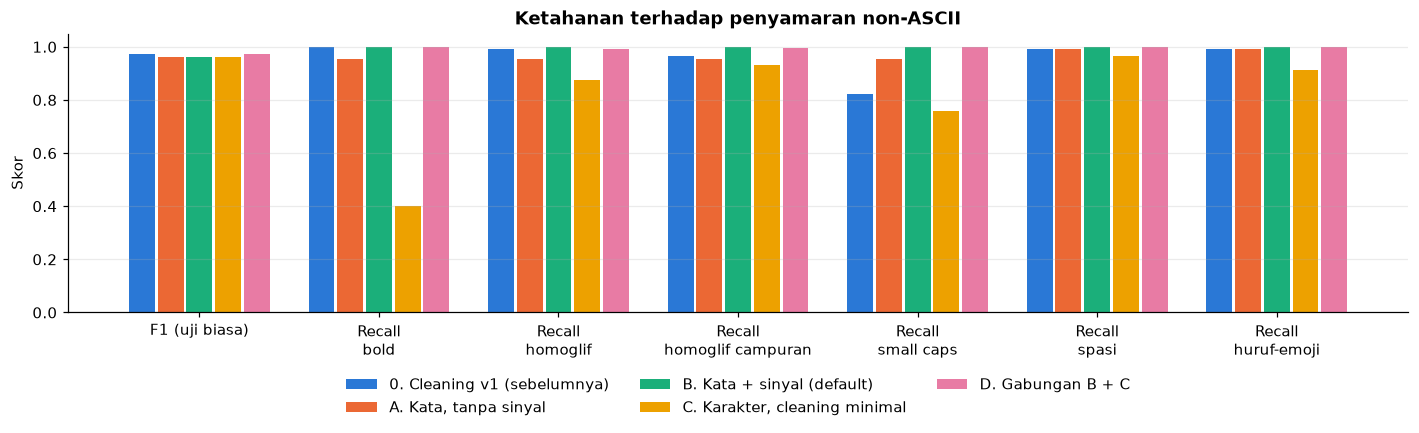

In [23]:
kolom_plot = [c for c in eksperimen_df.columns if c != "False positive"]
fig, ax = plt.subplots(figsize=(13, 4.4))
lebar = 0.8 / len(eksperimen_df)
for i, nama in enumerate(eksperimen_df.index):
    x = np.arange(len(kolom_plot)) + i * lebar - 0.4 + lebar / 2
    ax.bar(x, eksperimen_df.loc[nama, kolom_plot], width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(kolom_plot)), [k.replace("Recall samaran ", "Recall\n") for k in kolom_plot])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Skor")
ax.set_title("Ketahanan terhadap penyamaran non-ASCII")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.42), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [24]:
# Bobot fitur sinyal pada varian B: positif = mendorong ke "promosi judi"
b = VARIAN["B. Kata + sinyal (default)"]
fitur_b = b.named_steps["fitur"].get_feature_names_out()
coef_b = pd.Series(b.named_steps["clf"].coef_[0], index=[f.split("__", 1)[1] for f in fitur_b])
print("Koefisien fitur sinyal (Logistic Regression, varian B):")
print(coef_b.reindex(list(SINYAL)).round(3).to_string())
print()
emo = coef_b[coef_b.index.str.startswith("emo_")].sort_values()
print("Token emoji paling condong ke normal :", ", ".join(emo.index[:5]))
print("Token emoji paling condong ke judi   :", ", ".join(emo.index[-5:][::-1]))
print()
print("Proporsi data latih dengan tiap sinyal:")
for k in SINYAL:
    print(f"  {k:12s} judi {D_train.loc[y_train == 1, 'sinyal'].str.contains(k).mean():6.1%}"
          f" | normal {D_train.loc[y_train == 0, 'sinyal'].str.contains(k).mean():6.1%}")

Koefisien fitur sinyal (Logistic Regression, varian B):
xxfancy        4.292
xxhomoglyph    1.763
xxspaced       2.604
xxdecor        1.582
xxleet         0.891
xxinvisible   -0.169

Token emoji paling condong ke normal : emo_face_with_tears_of_joy, emo_grinning_face_with_sweat, emo_crying_face, emo_party_popper, emo_rolling_on_the_floor_laughing
Token emoji paling condong ke judi   : emo_star, emo_high_voltage, emo_yin_yang, emo_dizzy, emo_partying_face

Proporsi data latih dengan tiap sinyal:
  xxfancy      judi  50.6% | normal   0.6%
  xxhomoglyph  judi   8.3% | normal   0.0%


  xxspaced     judi   8.3% | normal   0.0%
  xxdecor      judi   3.4% | normal   0.0%
  xxleet       judi   2.8% | normal   1.4%
  xxinvisible  judi   0.9% | normal   3.3%


### Kesimpulan eksperimen

Hasil saat notebook ini diuji (angka bisa sedikit berbeda antar versi library):

Recall = proporsi komentar promosi yang disamarkan dan masih tertangkap.

| Varian | F1 uji biasa | FP | bold | homoglif | homoglif campuran | small caps | spasi | huruf-emoji |
|---|---|---|---|---|---|---|---|---|
| 0. Cleaning v1 (sebelumnya) | 0.972 | 8 | 0.998 | 0.991 | 0.966 | **0.821** | 0.993 | 0.993 |
| A. Kata, tanpa sinyal | 0.960 | 18 | 0.953 | 0.953 | 0.953 | 0.953 | 0.993 | 0.993 |
| B. Kata + kolom sinyal (**cleaning v2**, default) | 0.963 | 9 | **1.000** | **0.998** | **0.998** | **1.000** | **1.000** | **1.000** |
| C. Karakter, cleaning minimal | 0.963 | 8 | **0.400** | 0.876 | 0.930 | **0.760** | 0.964 | 0.913 |
| D. Gabungan B + C | **0.975** | **6** | **1.000** | 0.993 | 0.995 | **1.000** | **1.000** | **1.000** |

1. **Membiarkan non-ASCII apa adanya (C) rapuh.** Skor di data uji biasa bagus, tetapi begitu spammer mengganti gaya huruf,
   recall jatuh ke ~0.40 (bold) dan ~0.76 (small caps) - n-gram karakter huruf bold tidak mirip sama sekali dengan `pluto`.
2. **Normalisasi saja (A) tahan penyamaran tetapi kehilangan informasi** bahwa komentar itu disamarkan -> false positive paling banyak.
3. **Pada data uji biasa, v1 sedikit lebih tinggi dari v2 untuk Logistic Regression** (0.972 vs 0.963, selisih beberapa
   komentar). Dataset Kaggle hampir tidak memuat jenis samaran yang baru ditangani v2, jadi di data biasa keduanya setara.
4. **Keunggulan v2 ada pada ketahanan.** v1 menghapus yang tidak dikenalnya: ia masih bertahan pada homoglif campuran &
   huruf-emoji hanya karena penanda umum `xxdecor` ikut menyala (model mendeteksi "ada karakter aneh", bukan nama situsnya),
   dan pada **small caps** hurufnya terhapus tanpa jejak -> recall 0.82. v2 menerjemahkan semua samaran kembali ke kata
   aslinya (recall >= 0.99 di semua jenis) sehingga nama situs tetap terbaca - penting juga untuk NER / inventaris situs judi nanti.
5. **Gabungan (D)** paling baik secara keseluruhan (F1 tertinggi, false positive paling sedikit, tahan semua samaran) dan
   layak dijadikan model utama untuk implementasi ulang.
6. Dibanding **cleaning asli di `worker.py`** (notebook 04), perbedaannya jauh lebih besar: di sana huruf bold sama sekali
   tidak dinormalisasi dan hanya ~12% komentar promosi ber-huruf bold yang tertangkap.

**Prinsipnya: jangan buang non-ASCII, tapi juga jangan dipakai mentah - terjemahkan menjadi (a) teks yang terbaca,
(b) token emoji/aksara, dan (c) fitur penanda penyamaran. Yang tidak bisa diterjemahkan dicatat, bukan dihapus.**

Keterbatasan & pengembangan:
- nama situs baru yang belum ada di data latih tetap lebih sulit dikenali (token sinyal membantu, tetapi tidak menjamin)
- leetspeak sengaja tidak dinormalisasi; untuk NER nanti buat kolom terpisah berisi versi ter-normalisasi (`m4xw1n` -> `maxwin`)
- samaran di sini sintetis; pantau inventaris karakter tak dikenal (notebook 01) untuk trik nyata yang baru

## 8. Simpan model & informasi training

In [25]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
for nama, model in fitted.items():
    joblib.dump(model, os.path.join(OUTPUT_DIR, f"{nama.replace(' ', '_').lower()}.joblib"))

# Model eksperimen terbaik (varian D). Semua model menerima DataFrame dari siapkan_input().
joblib.dump(VARIAN["D. Gabungan B + C"], os.path.join(OUTPUT_DIR, "gabungan_kata_karakter.joblib"))

metrics_df.to_csv(os.path.join(OUTPUT_DIR, "metrics.csv"))
eksperimen_df.to_csv(os.path.join(OUTPUT_DIR, "eksperimen_cleaning.csv"))

info = {
    "dibuat": datetime.now().isoformat(timespec="seconds"),
    "dataset": "kaggle: yaemico/judionline",
    "kolom_teks": "komentar -> siapkan_input() -> kolom text_clean, sinyal, text_min",
    "catatan_penting": "Semua pipeline menerima DataFrame hasil siapkan_input() (fungsi cleaning yang sama).",
    "jumlah_data": {
        "awal": int(n_awal),
        "setelah_dedup": int(len(data)),
        "train_sebelum_balancing": int(len(X_train_full)),
        "train_setelah_balancing": int(len(X_train)),
        "test": int(len(X_test)),
        "test_distribusi_label": {int(k): int(v) for k, v in y_test.value_counts().items()},
    },
    "vectorizer": {"jenis": "TfidfVectorizer", "max_features": 5000},
    "parameter_model": {n: {k: str(v) for k, v in m.named_steps["clf"].get_params().items()} for n, m in fitted.items()},
    "metrik_uji": {n: {k: (None if pd.isna(v) else round(float(v), 4)) for k, v in h.items()} for n, h in hasil.items()},
    "model_terbaik_f1": terbaik,
    "voting": "prediksi 1 jika >= 3 dari 5 model memprediksi 1",
    "token_sinyal": SINYAL,
    "eksperimen_cleaning": {n: {k: round(float(v), 4) for k, v in r.items()} for n, r in eksperimen_df.iterrows()},
    "model_gabungan": "gabungan_kata_karakter.joblib - input sama: siapkan_input(teks)",
    "fitur": "TF-IDF(text_clean, max_features=5000) + biner(sinyal); model gabungan + TF-IDF karakter(text_min)",
    "versi": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
              "pandas": pd.__version__, "numpy": np.__version__},
}
with open(os.path.join(OUTPUT_DIR, "training_info.json"), "w") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

shutil.make_archive("models", "zip", OUTPUT_DIR)
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f"{f:35s} {os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024:8.1f} KB")
print("\nArsip: models.zip")

eksperimen_cleaning.csv                  0.8 KB
gabungan_kata_karakter.joblib         2340.4 KB
knn.joblib                             537.1 KB
logistic_regression.joblib             219.9 KB
metrics.csv                              1.0 KB
naive_bayes.joblib                     337.2 KB
random_forest.joblib                 16262.5 KB
svm.joblib                             404.2 KB
training_info.json                       6.8 KB

Arsip: models.zip


In [26]:
# Cek: model yang disimpan bisa dimuat ulang dan hasilnya sama
m = joblib.load(os.path.join(OUTPUT_DIR, "svm.joblib"))
assert (m.predict(X_test) == prediksi["SVM"][0]).all()
print("OK - model berhasil dimuat ulang")

OK - model berhasil dimuat ulang


In [27]:
# Di Google Colab: unduh models.zip untuk dipakai di notebook 01 (bagian prediksi)
try:
    from google.colab import files
    files.download("models.zip")
except ImportError:
    print("Bukan di Colab - models.zip ada di folder kerja:", os.path.abspath("models.zip"))

Bukan di Colab - models.zip ada di folder kerja: /home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/notebooks/models.zip


## Catatan

- Skor sangat tinggi karena promosi judi di dataset ini didominasi **nama situs** (`alexis17`, `sgi88`, ...) dan kalimat template.
  Lihat hasil kalimat `zeus123` di atas: nama situs baru yang tidak ada di data latih lebih sulit dikenali.
- Ide pengembangan: TF-IDF karakter n-gram (lebih tahan variasi ejaan), fitur pola `huruf+angka`, atau model transformer (IndoBERT).
- Model disimpan sebagai `Pipeline` sehingga cukup: `model.predict(siapkan_input(["teks komentar"]))`.